# Forecasting California Retail Gasoline Prices, 1–12 Weeks Ahead
**UCLA Anderson MSBA · Time Series Analysis & Forecasting · Group Project (2026)**

**Research question:** *Can we forecast California retail gasoline prices 1–12 weeks ahead, and what drives them?*

This notebook runs the whole project end to end. Each step calls the same functions as `src/run_all.py`, which live in `src/`:

| Step | What | Module |
|---|---|---|
| 1 | Profile the 8 EIA series | `src/data_prep.py` |
| 2 | Build a weekly panel with **no look-ahead** and test it | `src/data_prep.py`, `src/features.py` |
| 3 | Exploratory story: the 2026 crude shock, California's premium, seasonality | `src/visualize.py` |
| 4 | Models: random walk, seasonal naive and seasonal mean, ARIMA, ETS, Ridge, GBM, ensembles | `src/models.py` |
| 5 | Rolling-origin backtest, Jan 2022 to latest, refit every 4 weeks | `src/backtest.py` |
| 6 | Validation (2022–24) → model choice → untouched holdout (2025–26), regimes, DM tests | `src/backtest.py` |
| 7 | 12-week forecast with empirical 80% and 90% intervals; Brent scenario | `src/forecast.py` |
| 8 | Option A: honest LLM-forecast comparison kit | `src/llm_kit.py` |

The full backtest takes about 4 minutes. Set `USE_CACHE = True` to reuse `outputs/forecasts/backtest_forecasts.csv`.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown

# make the repo root importable whether the notebook runs from notebooks/ or the root
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, data_prep as D, features as F, models as M, backtest as B, forecast as FC, visualize as P

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
C.set_seeds()
C.make_dirs()
USE_CACHE = False
show = lambda path: display(Image(filename=str(path), width=950))

## 1. Data profile
The folder contains eight EIA series. Retail prices are weekly on Mondays. Crude is daily, and its blanks are market holidays, which we drop. Inventories and refinery utilisation are weekly on Fridays; PADD5 utilisation only starts in June 2010.

In [2]:
raw = D.load_raw()
prof = D.profile(raw)
prof

,series,file,start,end,n_obs,blank_rows,frequency,weekday,max_gap_days,min,max,last,usable_lag_days
0,ca,ca_gas.csv,2000-05-22,2026-10-05,1377,0,weekly,Monday,7,1.10,6.27,6.227,0
1,us,us_gas.csv,2000-01-03,2026-10-05,1397,0,weekly,Monday,7,1.06,5.01,4.354,0
2,brent,brent.csv,2000-01-04,2026-10-06,6481,500,daily (business),Mon-Fri,11,9.12,143.95,125.440,3
3,wti,wti.csv,2000-01-04,2026-10-06,6332,649,daily (business),Mon-Fri,8,-36.98,145.31,96.240,3
4,stocks_p5,gas_stocks_padd5.csv,1990-01-05,2026-10-02,1918,0,weekly,Friday,7,23876.00,36779.00,27856.000,10
5,stocks_us,gas_stocks_us.csv,1990-01-05,2026-10-02,1918,0,weekly,Friday,7,178739.00,263234.00,204744.000,10
6,util_p5,refinery_util_padd5.csv,2010-06-04,2026-10-02,853,0,weekly,Friday,7,58.70,99.20,95.200,10
7,util_us,refinery_util_us.csv,1990-11-02,2026-10-02,1875,0,weekly,Friday,7,56.00,100.50,92.700,10


## 2. Weekly panel with no look-ahead
Everything is indexed on the **Monday retail-price date T** (the forecast origin).

* **Crude:** the last close on or before the prior Friday (T − 3 days).
* **EIA stocks and utilisation:** the week ending Friday F is released the following Wednesday, so we use it only from Monday **F + 10**.
* **Features:** past CA log changes (1w, 4w); Brent log changes (1w, 4w, 12w); the retail-minus-crude margin (CA − Brent/42) minus its 52-week mean; the CA–US spread minus its 52-week mean; PADD5 and US inventories as % deviation from the same-week 5-year average; PADD5 utilisation and its 4-week change; week-of-year sin/cos.
* **Seasonal expectation `seas_h`:** the average log change over the next *h* weeks at this week-of-year in the prior 10 calendar years. Every term ends at least 40 weeks before T.
* **Targets** `tgt_h = ln(CA_{T+h}) − ln(CA_T)`.

In [3]:
panel = F.build_panel(raw)
print(panel.shape, panel.index[0].date(), "→", panel.index[-1].date())
panel[F.FEATURES_BASE + ["seas_4", "tgt_4"]].tail(4).T.round(4)

(1377, 47) 2000-05-22 → 2026-10-05


date,2026-09-14,2026-09-21,2026-09-28,2026-10-05
ca_chg_1w,0.0259,0.0298,0.0305,0.0061
ca_chg_4w,0.0767,0.0966,0.1144,0.0923
brent_chg_1w,0.1439,0.0135,-0.0310,0.1554
brent_chg_4w,0.2492,0.2108,0.2566,0.2817
brent_chg_12w,0.3834,0.5339,0.5242,0.6004
margin_dev,0.0246,0.1571,0.4170,-0.0116
spread_dev,0.0815,0.0941,0.2855,0.4240
inv_p5_dev,-4.5783,-3.8737,-4.2252,-0.6573
inv_us_dev,-5.1702,-4.7765,-5.6872,-6.8028
util_p5,93.2000,94.9000,94.5000,93.4000


**Look-ahead test.** For 26 origins we rebuild the panel from raw data truncated to what was *published* by that origin, and require the features to be identical to the full-sample panel. We then test the test: if EIA data are aligned with a 3-day lag instead of the true 10 days, the check must fail.

In [4]:
la = F.check_no_lookahead(panel, raw)
print(f"{la.ok.sum()}/{len(la)} origins identical (max abs diff {la.max_abs_diff.max():.1e})")
print("Leak-injection test caught the leak:", F.lookahead_mutation_test(raw, panel))

26/26 origins identical (max abs diff 0.0e+00)


Leak-injection test caught the leak: True


## 3. The story in the data
### 3a. The 2026 crude shock and California's premium
Brent went from about \$62 in December 2025 to more than \$125 in March–April 2026. It eased to roughly \$70 in June and surged again to about \$135 by early October. California pump prices followed, peaking near \$6 in May and reaching \$6.23 in the latest week. To keep a single y-axis, we plot crude in $/gal (Brent ÷ 42); the vertical gap between the lines is the retail margin.

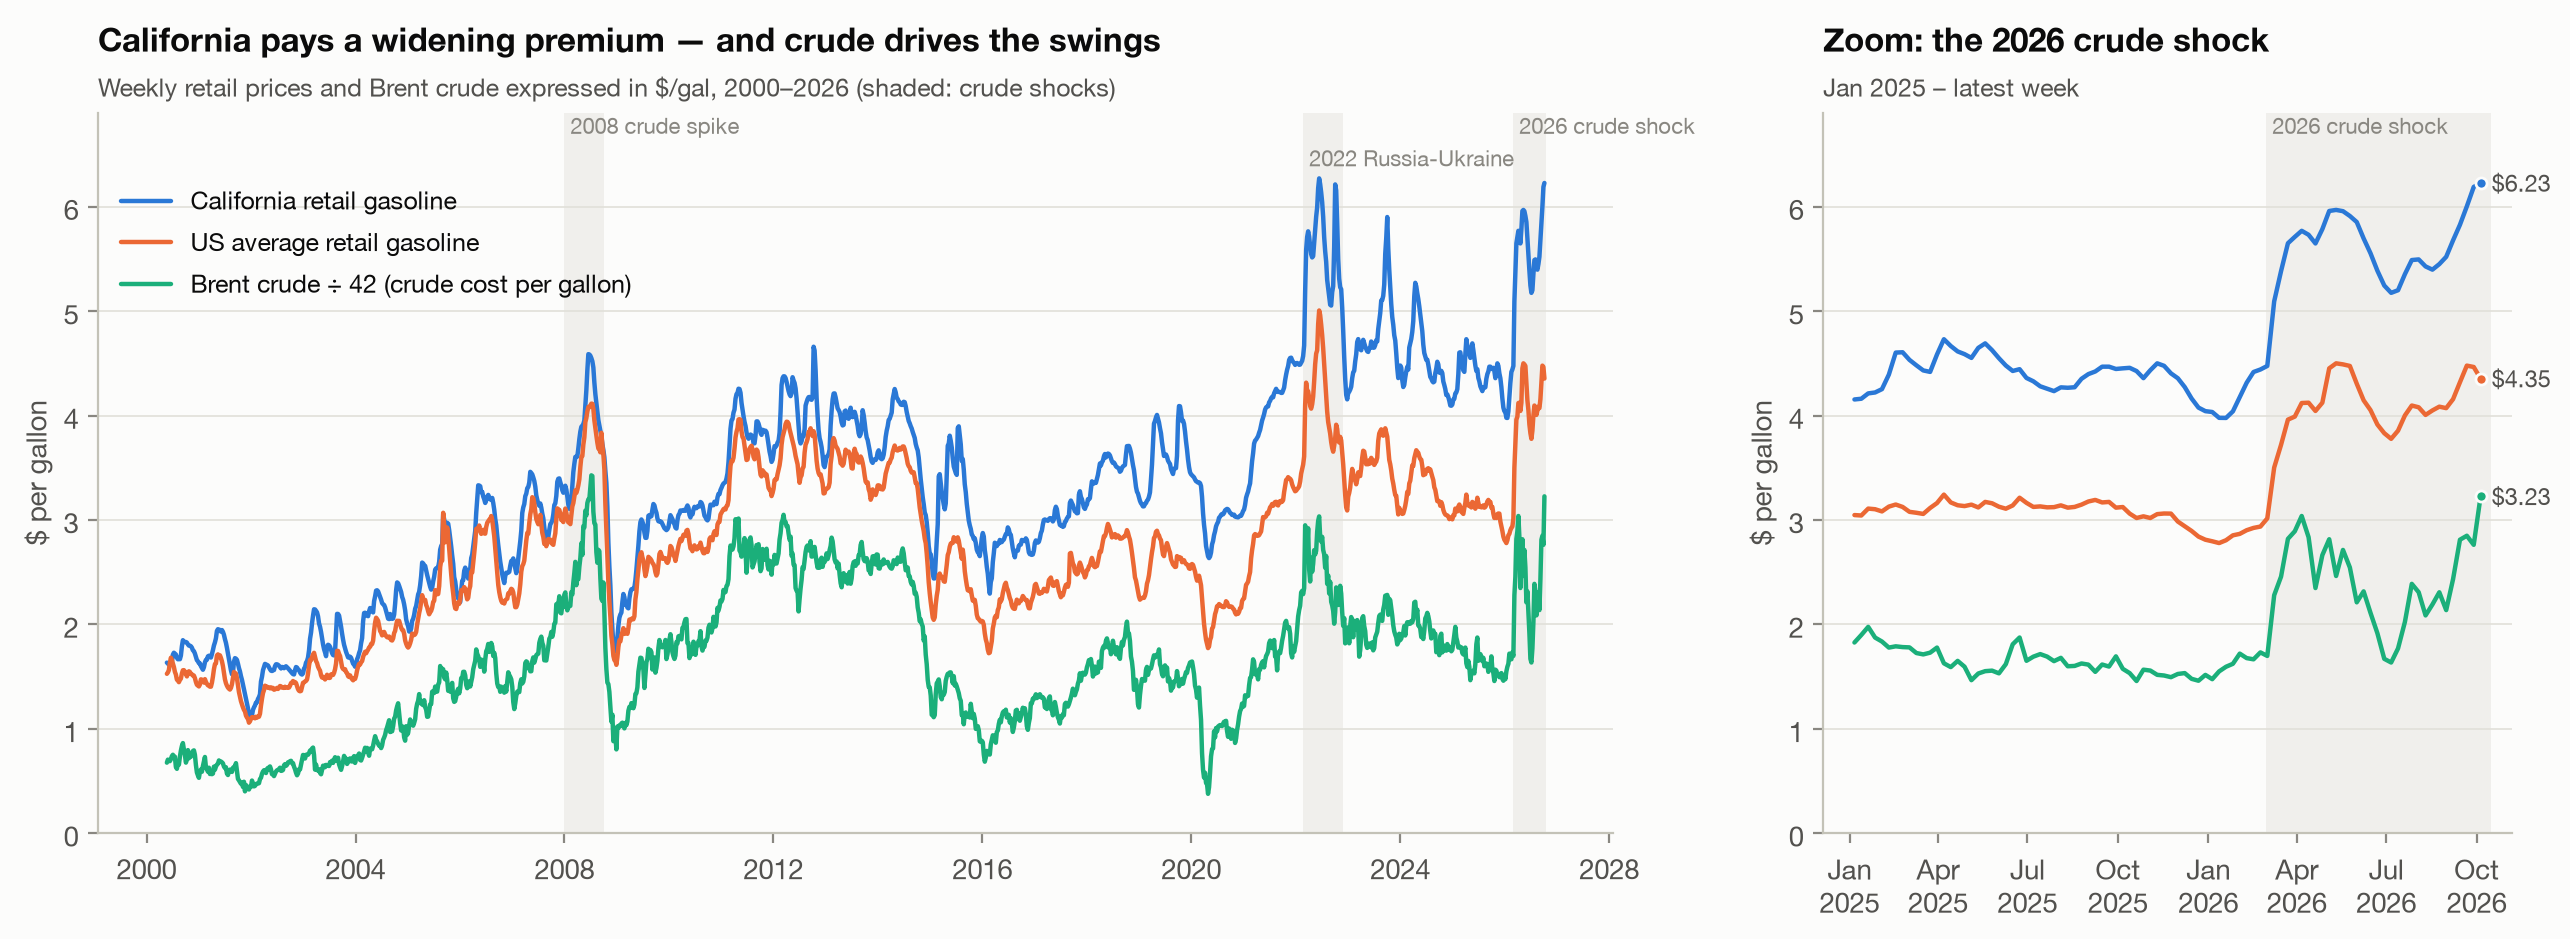

In [5]:
show(P.fig_prices(panel))

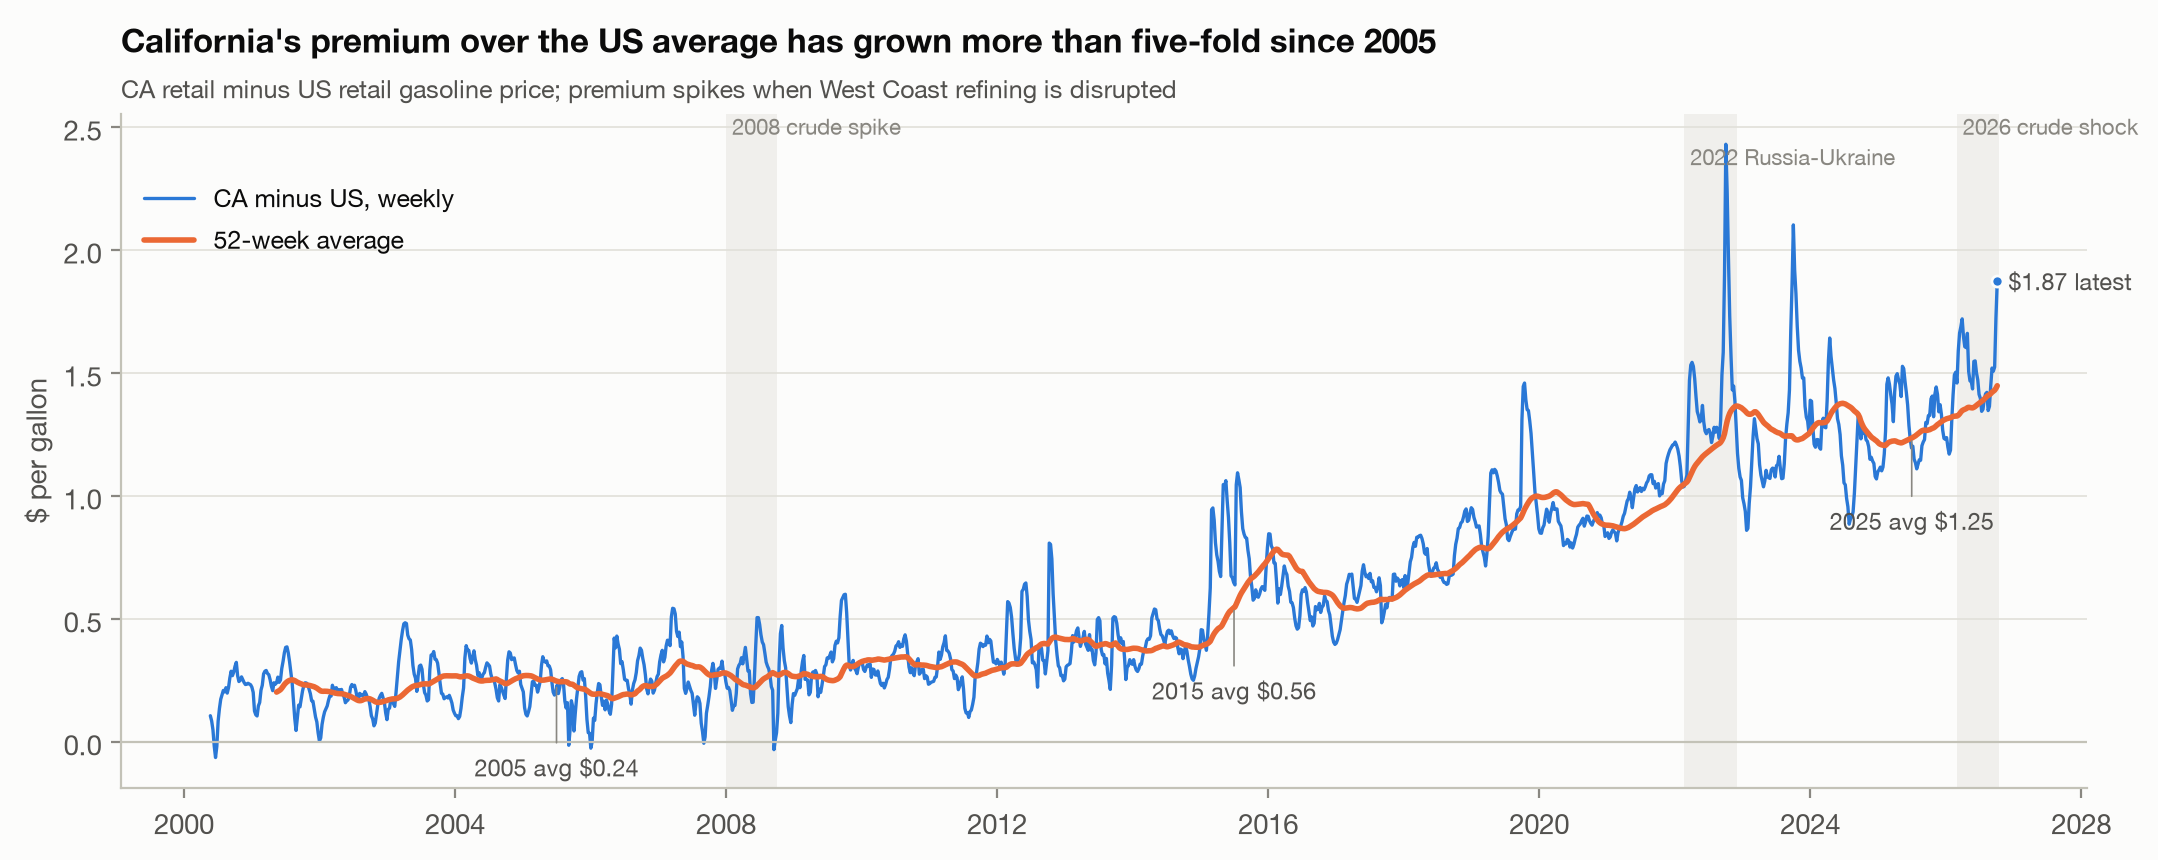

In [6]:
show(P.fig_premium(panel))

California's premium over the US average rose from about \$0.25 in the mid-2000s to about \$1.25 in 2025. Its spikes coincide with West Coast refinery outages. The causes are structural: California's own cleaner-burning blend, higher taxes and fees, and an isolated refining market.

### 3b. Seasonality: the strongest single signal

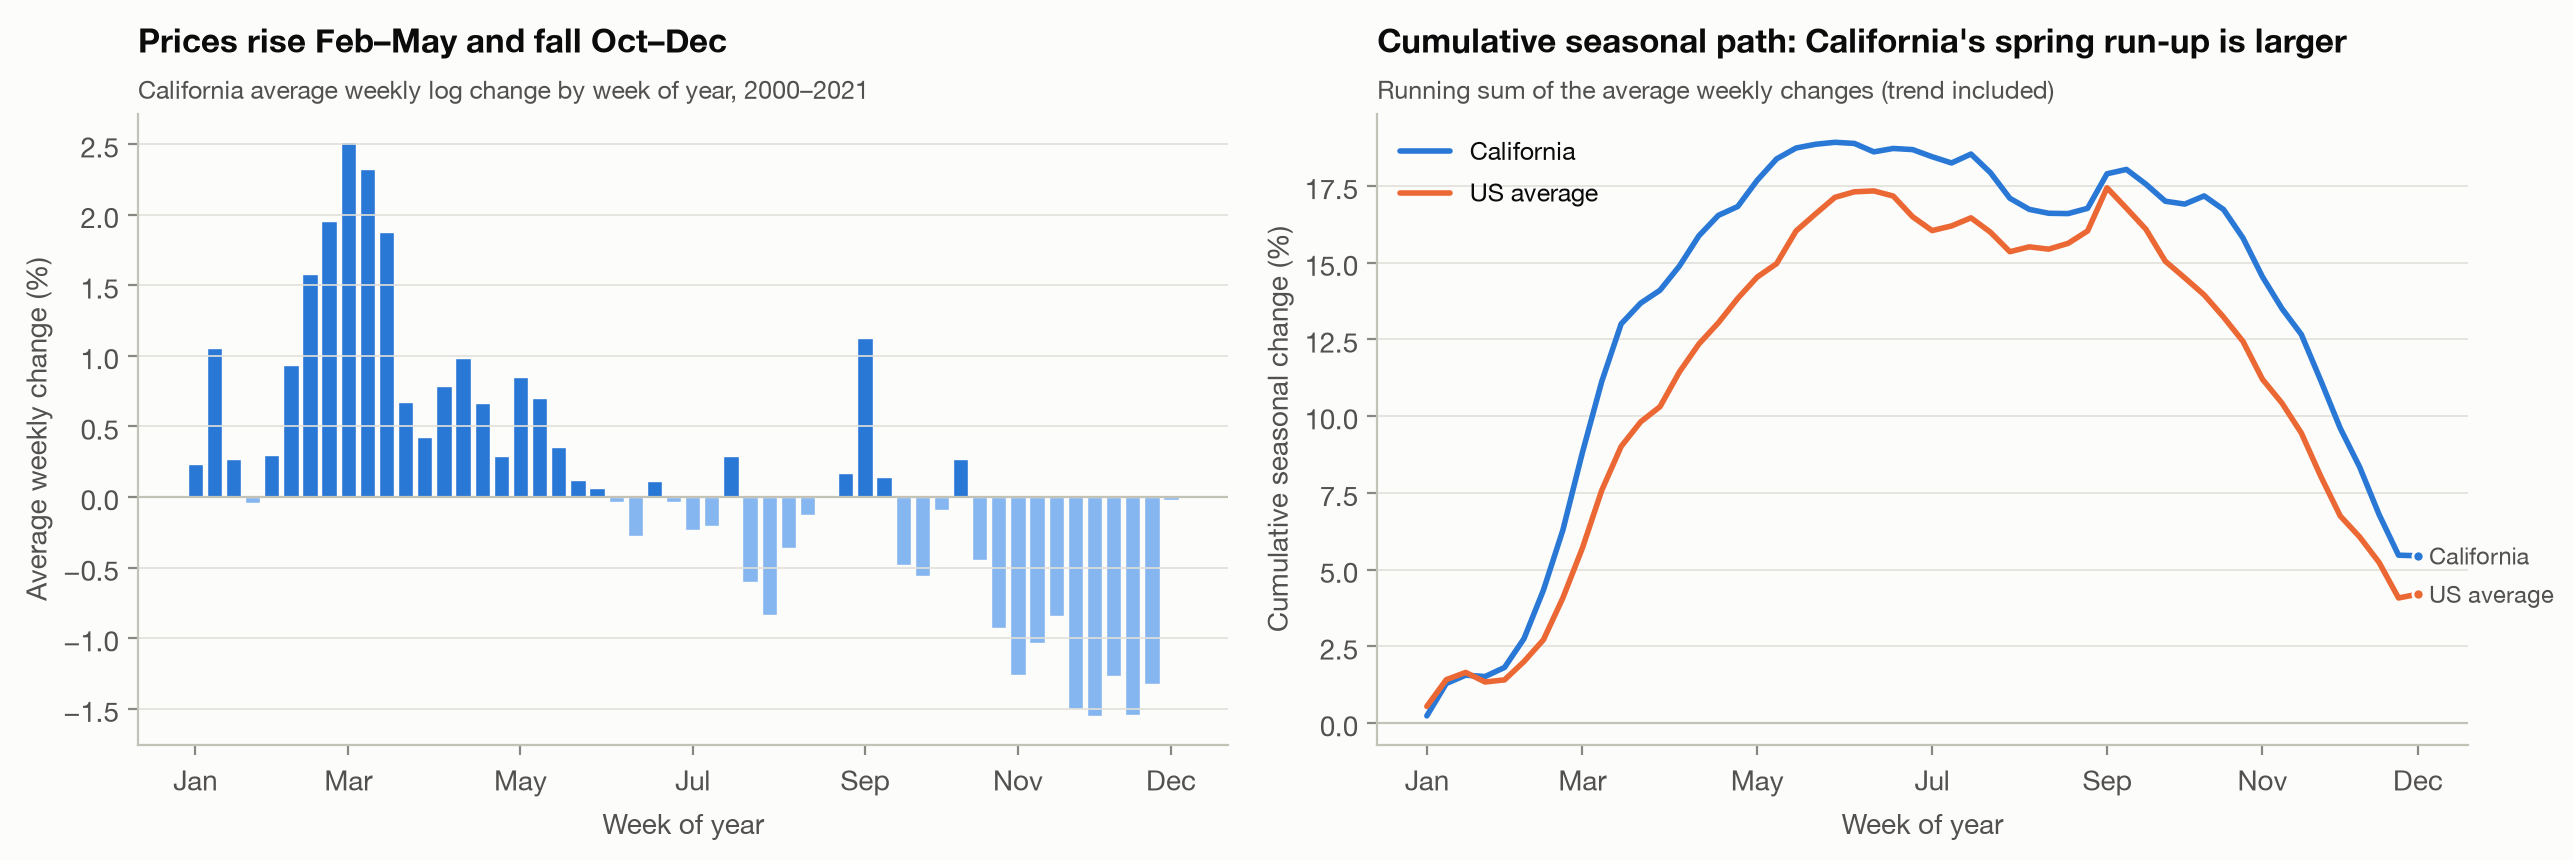

In [7]:
show(P.fig_seasonal(panel))

On average, prices climb from February to May (refinery maintenance, then the switch to summer blend) and fall from October to December (winter blend and lower demand). Seasonality was the strongest signal in our first pass, which is why we build the explicit *seasonal expectation* feature.

### 3c. Margins absorb crude shocks; inventories carry a weak signal

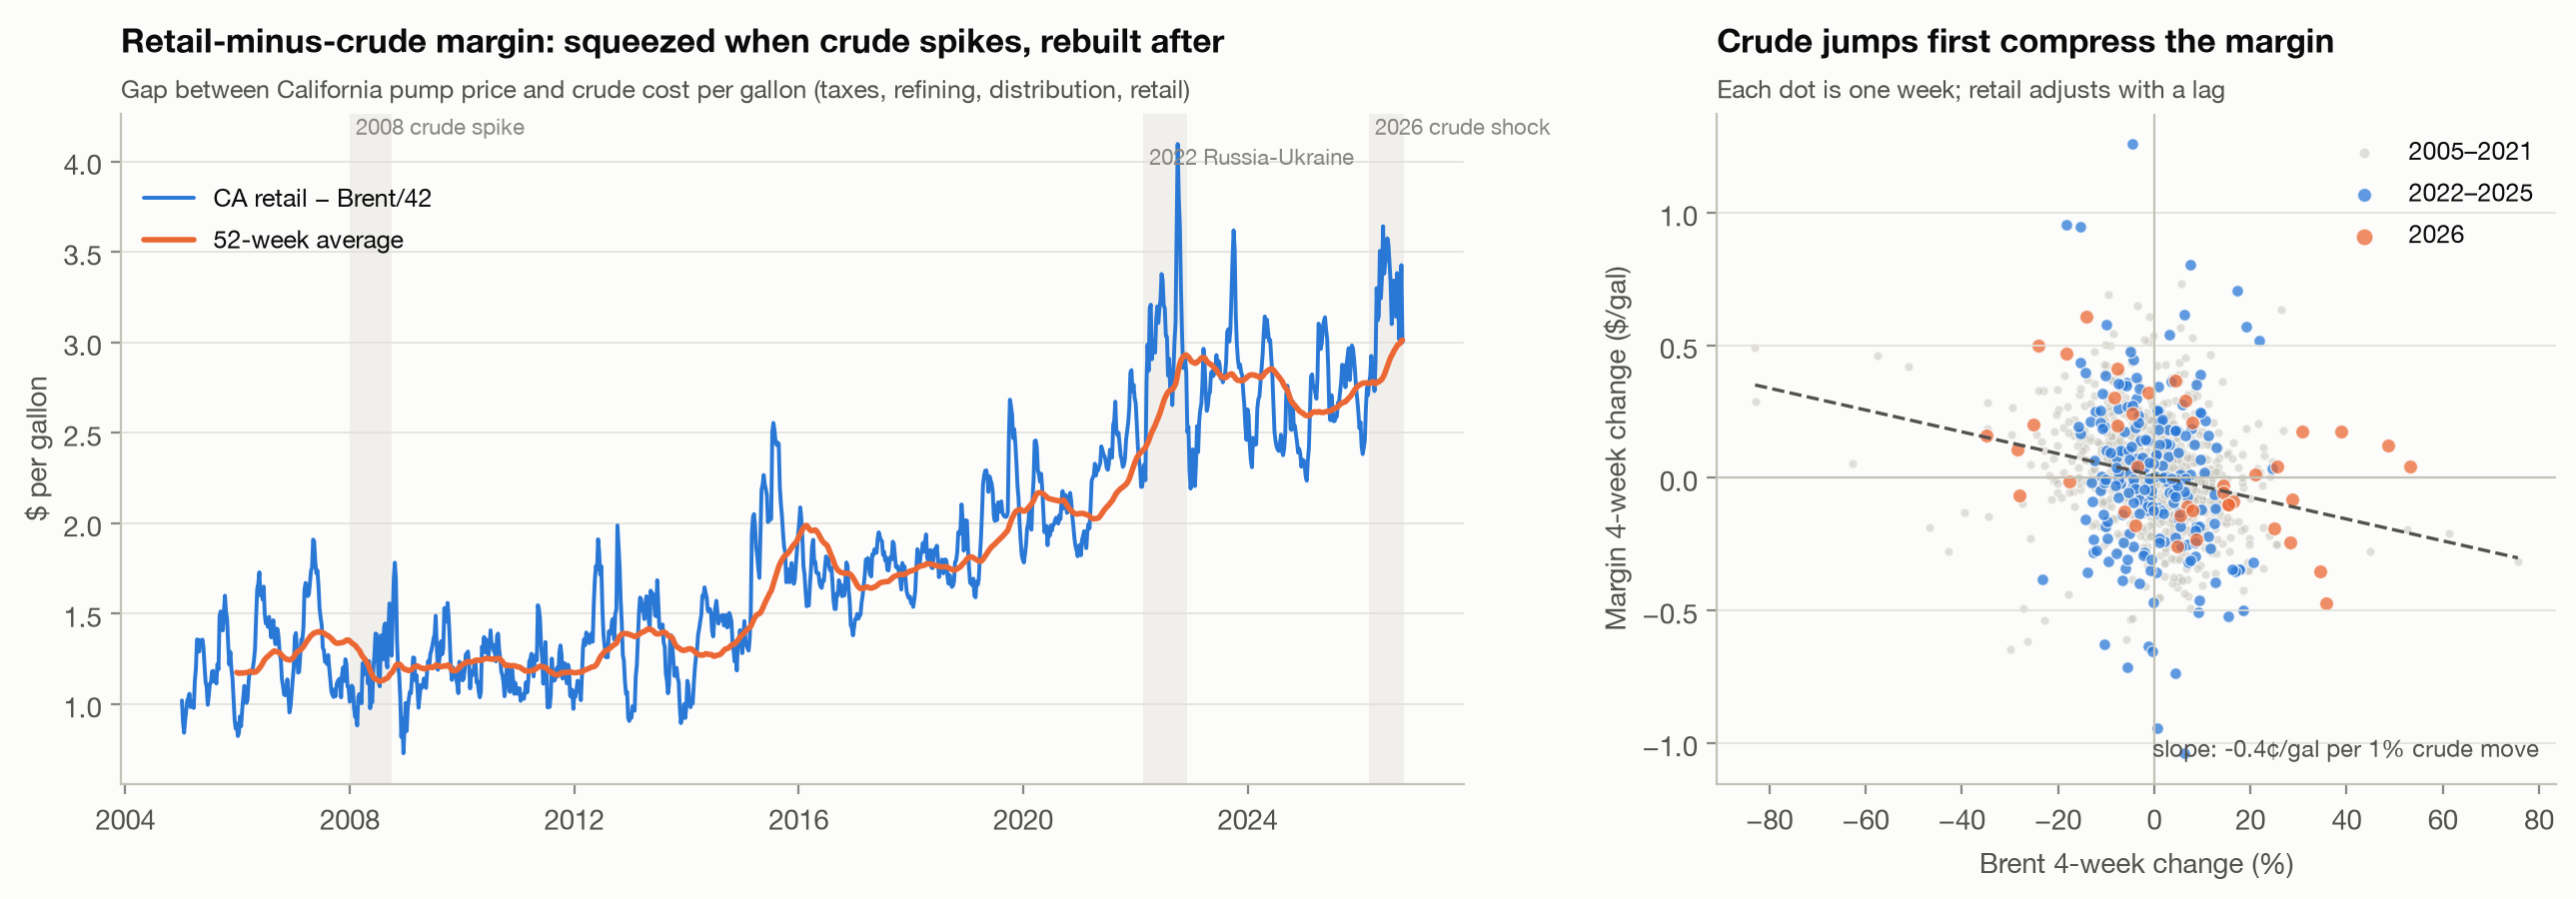

In [8]:
show(P.fig_margin(panel))

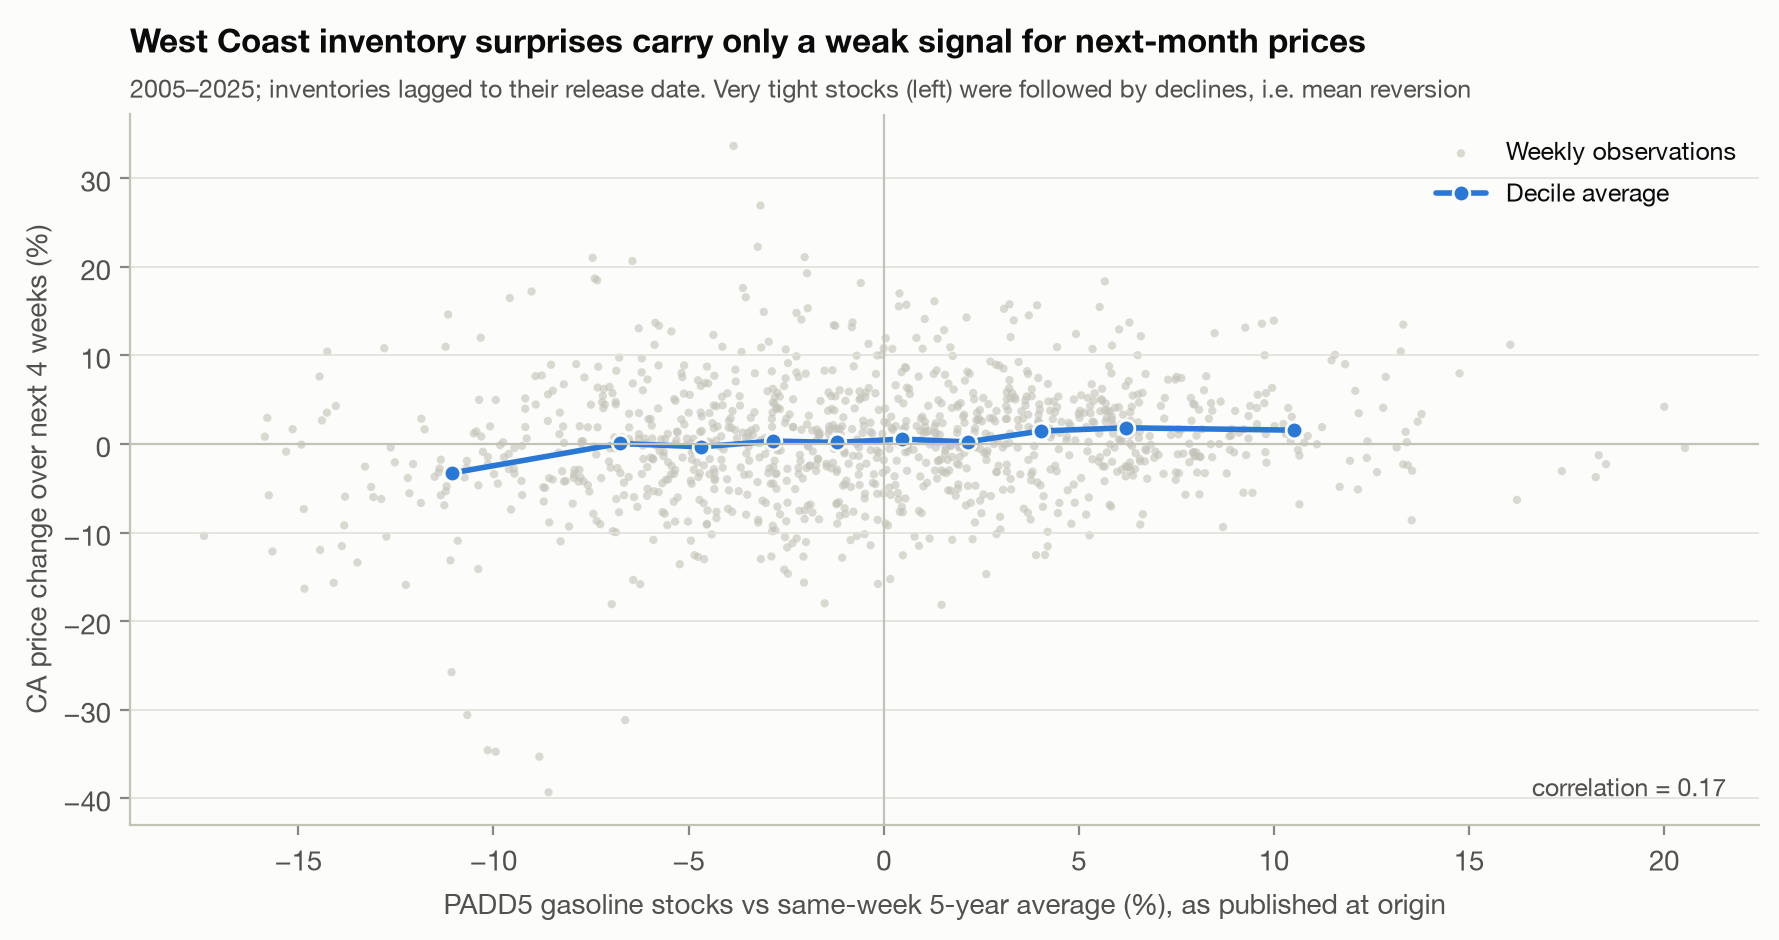

In [9]:
show(P.fig_inventory(panel))

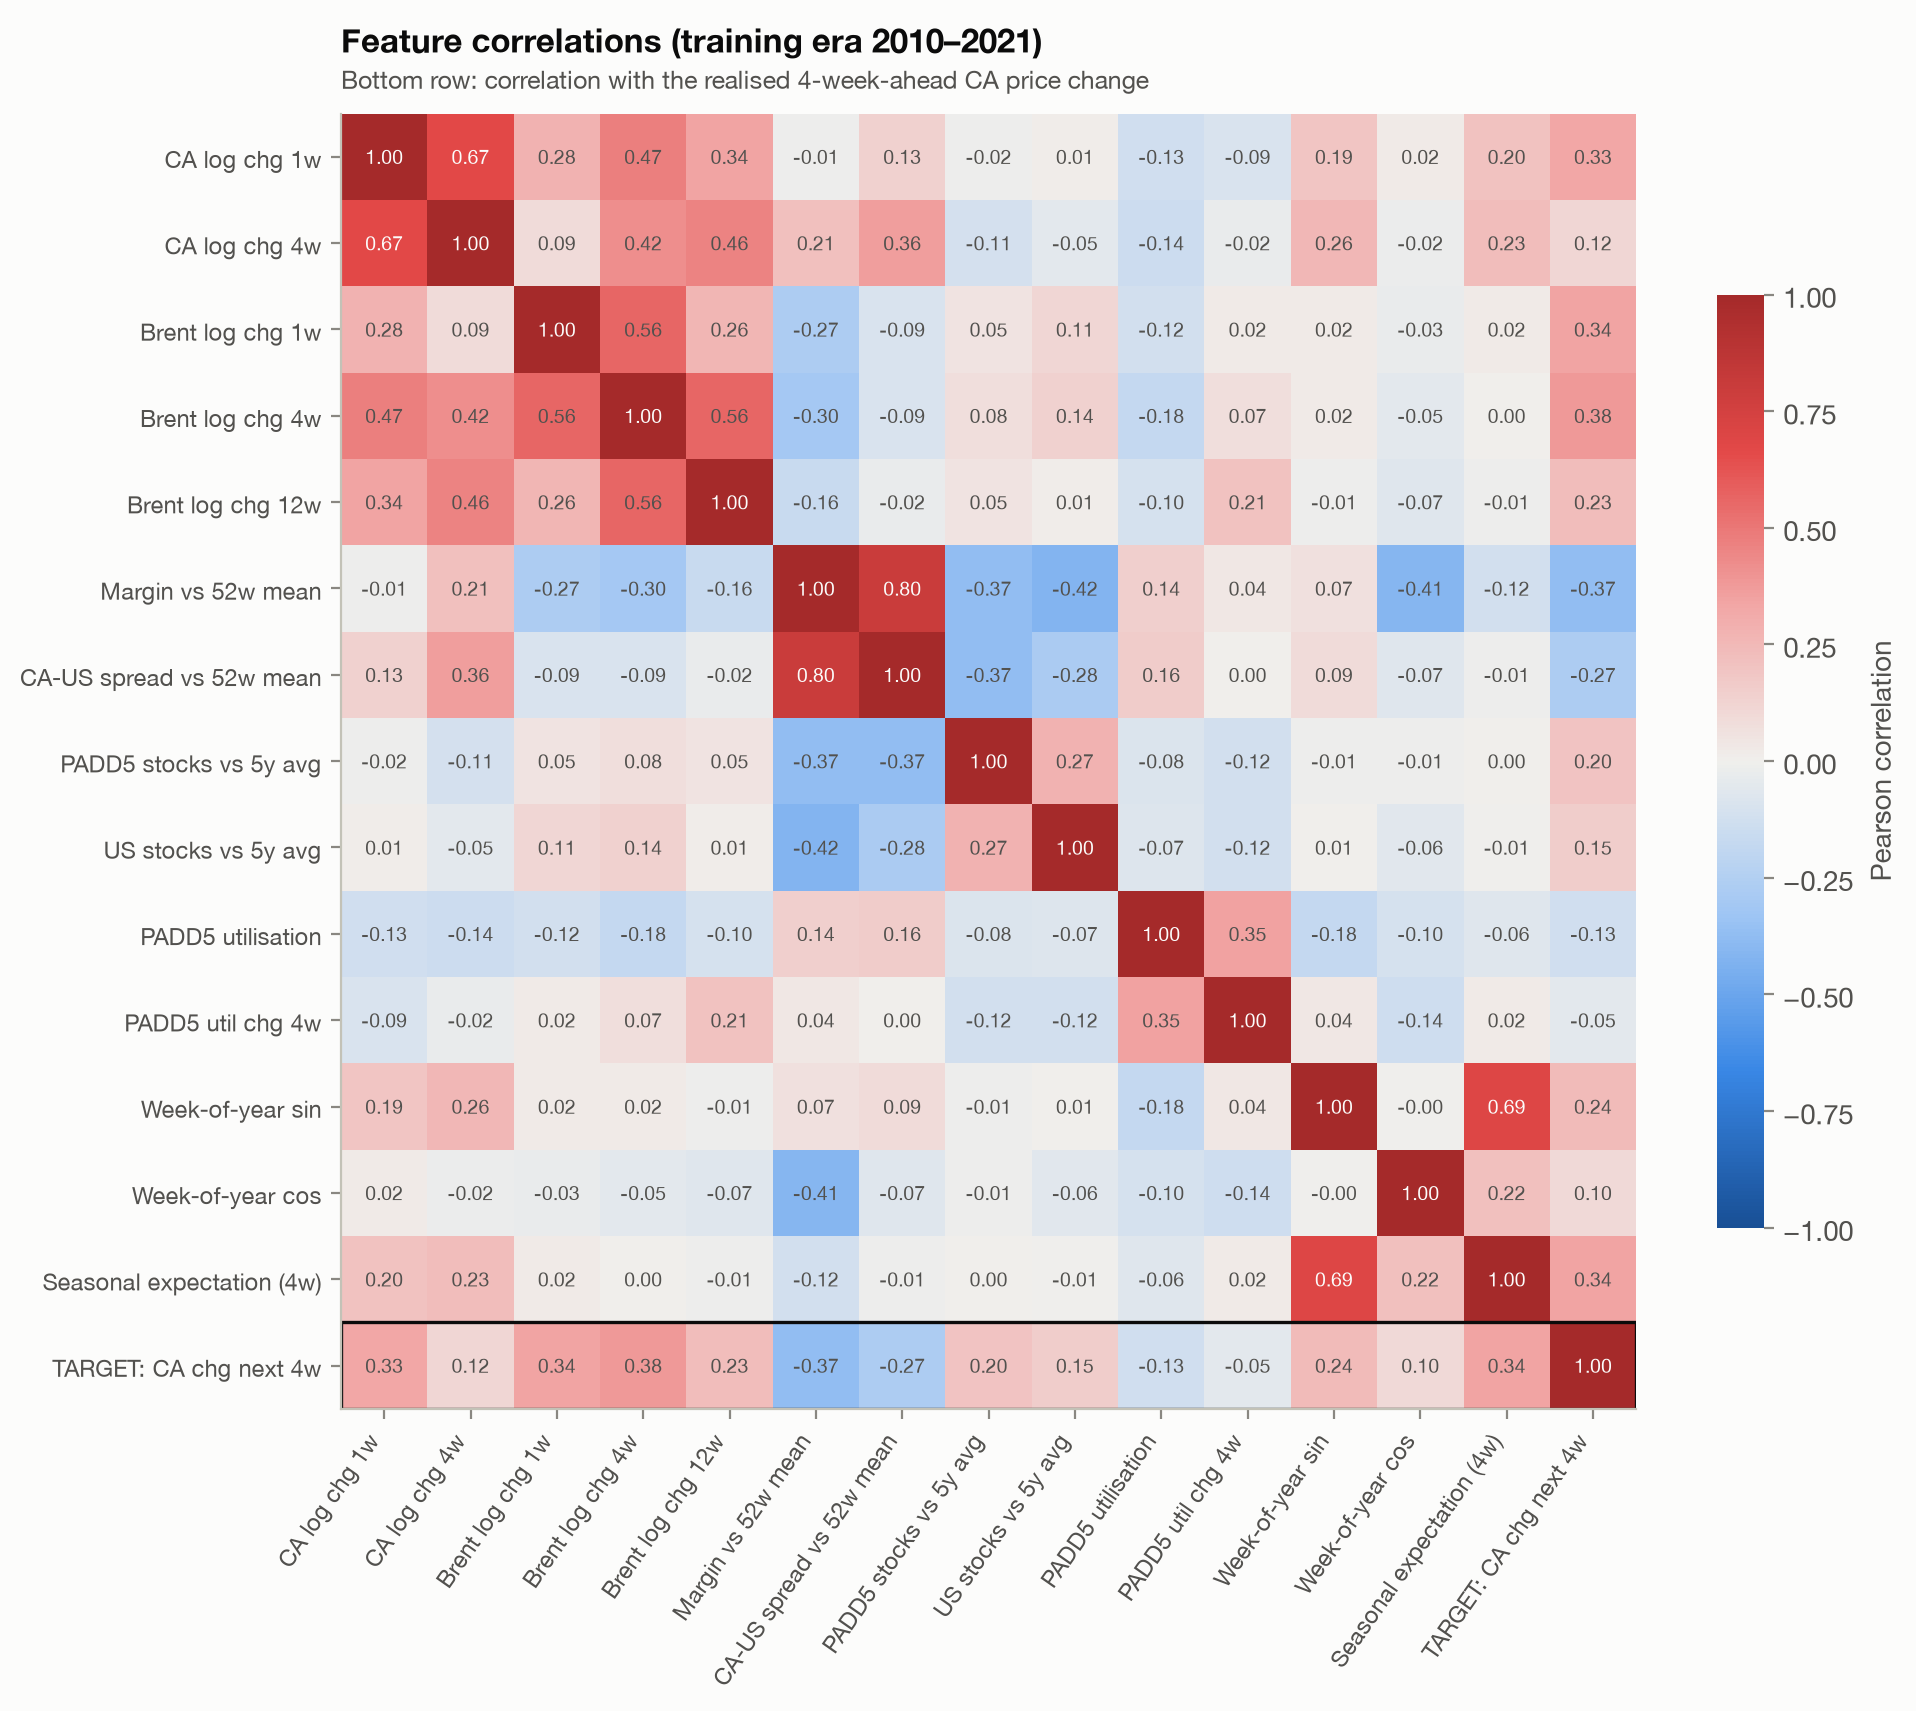

In [10]:
show(P.fig_corr(panel))

* When crude jumps, the margin is squeezed first and retail catches up over the following weeks ("rockets and feathers"). The margin deviation is a mean-reverting predictor: its correlation with the next 4-week change is −0.37.
* Brent momentum (4w change) and the seasonal expectation are the most positively correlated predictors of the 4-week-ahead change.
* The inventory signal is weak (correlation of about 0.2) and partly seasonal. Stocks are seasonally high in late winter, just before the spring run-up.

## 4. Models
| Model | Description |
|---|---|
| Random walk | No change. The benchmark. |
| Seasonal naive | Last year's change over the same weeks, applied to today's level |
| Seasonal mean (10y) | The `seas_h` feature itself, i.e. the average same-season change over the prior 10 years |
| ARIMA(p,1,q) | Order chosen by AIC on **pre-2022 data only**; parameters re-estimated at each refit |
| ETS damped | Holt additive damped trend on log price |
| Ridge / GBM | **Direct** multi-horizon regressions, one per h, with and without the seasonal feature |
| Ensembles | Equal-weight averages of log-change forecasts, with members fixed in advance |

In [11]:
aic = M.select_arima_order(panel)
best = aic.iloc[0]
order, trend = (int(best.p), 1, int(best.q)), best.trend
print("Selected ARIMA order:", order, "trend:", trend)
aic.head(8).round(1)

Selected ARIMA order: (3, 1, 2) trend: n


,p,d,q,trend,aic,bic
0,3,1,2,n,-5944.2,-5914.0
1,1,1,3,n,-5940.2,-5915.1
2,1,1,3,t,-5938.6,-5908.5
3,1,1,0,n,-5938.4,-5928.4
4,2,1,3,n,-5938.3,-5908.1
5,3,1,3,n,-5937.9,-5902.7
6,3,1,1,n,-5936.9,-5911.8
7,1,1,0,t,-5936.8,-5921.7


## 5. Rolling-origin backtest
* Weekly origins from 3 Jan 2022 to the latest date, with an expanding window and parameters re-estimated every 4 weeks.
* Direct regressions train only on rows whose **target date ≤ origin**. This is asserted inside `DirectRegression.fit`.
* All 12 horizons are forecast, because the fan chart needs them. Tables report h = 1, 4, 8, 12.

In [12]:
models = M.make_models(order, trend)
cache = C.FORECAST_DIR / "backtest_forecasts.csv"
t0 = time.time()
if USE_CACHE and cache.exists():
    bt = pd.read_csv(cache, parse_dates=["origin", "target_date"])
else:
    bt = B.run_backtest(panel, models)
    bt.to_csv(cache, index=False)
print(f"{bt.origin.nunique()} origins × {bt.model.nunique()} models × 12 horizons in {time.time()-t0:.0f}s")

249 origins × 13 models × 12 horizons in 306s


## 6. Validation → model choice → holdout
We choose the top model by mean RMSE relative to the random walk over h ∈ {1, 4, 8, 12}, **on targets in 2022–2024 only**. We then report its accuracy on 2025–2026 targets, which played no part in the choice.

In [13]:
t_valid = B.accuracy_table(bt, B.by_year(*C.VALID_YEARS))
t_hold = B.accuracy_table(bt, B.by_year(*C.HOLDOUT_YEARS))
top, ranking = B.select_top_model(t_valid)
ranking = ranking.join(t_hold.groupby("model").RelRMSE.mean().rename("holdout_mean_RelRMSE"))
print("Top model (validation):", top)
ranking.round(3)

Top model (validation): Ens: ML (+seasonal)


,mean_RelRMSE,mean_MAE,mean_DirAcc,holdout_mean_RelRMSE
model,,,,
Ens: ML (+seasonal),0.807,0.275,69.983,0.837
GBM + seasonal,0.814,0.275,71.117,0.853
GBM,0.817,0.276,69.461,0.847
Ridge + seasonal,0.825,0.285,69.856,0.844
Ens: all models,0.827,0.279,71.157,0.844
Seasonal mean (10y),0.836,0.270,71.227,0.833
Ridge,0.857,0.302,67.666,0.883
Ens: statistical,0.894,0.300,68.635,0.876
Ens: RW + seasonal mean,0.901,0.293,71.227,0.900


In [14]:
display(Markdown("**Validation 2022–24: RMSE relative to random walk**")); display(B.wide(t_valid).round(3))
display(Markdown("**Holdout 2025–26: RMSE relative to random walk**")); display(B.wide(t_hold).round(3))

**Validation 2022–24: RMSE relative to random walk**

h,h=1,h=4,h=8,h=12
model,,,,
ARIMA,0.776,0.957,0.969,0.971
ETS damped,0.810,1.087,1.182,1.264
Ens: ML (+seasonal),0.748,0.835,0.849,0.796
Ens: RW + seasonal mean,0.947,0.917,0.879,0.861
Ens: all models,0.768,0.844,0.858,0.838
Ens: statistical,0.776,0.916,0.935,0.949
GBM,0.758,0.830,0.894,0.784
GBM + seasonal,0.750,0.828,0.886,0.791
Random walk,1.000,1.000,1.000,1.000


**Holdout 2025–26: RMSE relative to random walk**

h,h=1,h=4,h=8,h=12
model,,,,
ARIMA,0.818,0.952,0.944,0.979
ETS damped,0.842,1.035,1.044,1.131
Ens: ML (+seasonal),0.806,0.895,0.830,0.819
Ens: RW + seasonal mean,0.941,0.905,0.881,0.875
Ens: all models,0.809,0.880,0.836,0.850
Ens: statistical,0.799,0.897,0.882,0.926
GBM,0.824,0.903,0.843,0.819
GBM + seasonal,0.813,0.909,0.856,0.833
Random walk,1.000,1.000,1.000,1.000


In [15]:
cols = ["model", "h", "n", "MAE", "RMSE", "MAPE", "DirAcc", "RelRMSE", "DM_stat", "DM_p"]
t_hold[t_hold.model.isin([top, "Random walk", "Seasonal mean (10y)", "ARIMA", "Ridge + seasonal"])][cols].round(3)

,model,h,n,MAE,RMSE,MAPE,DirAcc,RelRMSE,DM_stat,DM_p
0,ARIMA,1,92.0,0.060,0.092,1.220,75.000,0.818,-3.229,0.002
1,ARIMA,4,92.0,0.232,0.319,4.615,61.957,0.952,-0.883,0.379
2,ARIMA,8,92.0,0.346,0.489,6.884,58.696,0.944,-0.922,0.359
3,ARIMA,12,92.0,0.454,0.641,8.832,52.174,0.979,-0.532,0.596
8,Ens: ML (+seasonal),1,92.0,0.056,0.091,1.133,79.348,0.806,-2.887,0.005
9,Ens: ML (+seasonal),4,92.0,0.206,0.299,4.050,70.652,0.895,-1.184,0.239
10,Ens: ML (+seasonal),8,92.0,0.303,0.430,5.949,73.913,0.830,-1.398,0.166
11,Ens: ML (+seasonal),12,92.0,0.342,0.536,6.464,78.261,0.819,-1.446,0.152
32,Random walk,1,92.0,0.077,0.113,1.568,NaN,1.000,NaN,NaN
33,Random walk,4,92.0,0.234,0.335,4.673,NaN,1.000,NaN,NaN


MAE and RMSE are in $/gal. DirAcc is the share of forecasts that called the direction of change correctly; it is undefined for the random walk. DM is the Diebold–Mariano test against the random walk, using squared-error loss, Newey–West variance with lag h−1 and the Harvey–Leybourne–Newbold correction. A negative statistic means the model beats the random walk.

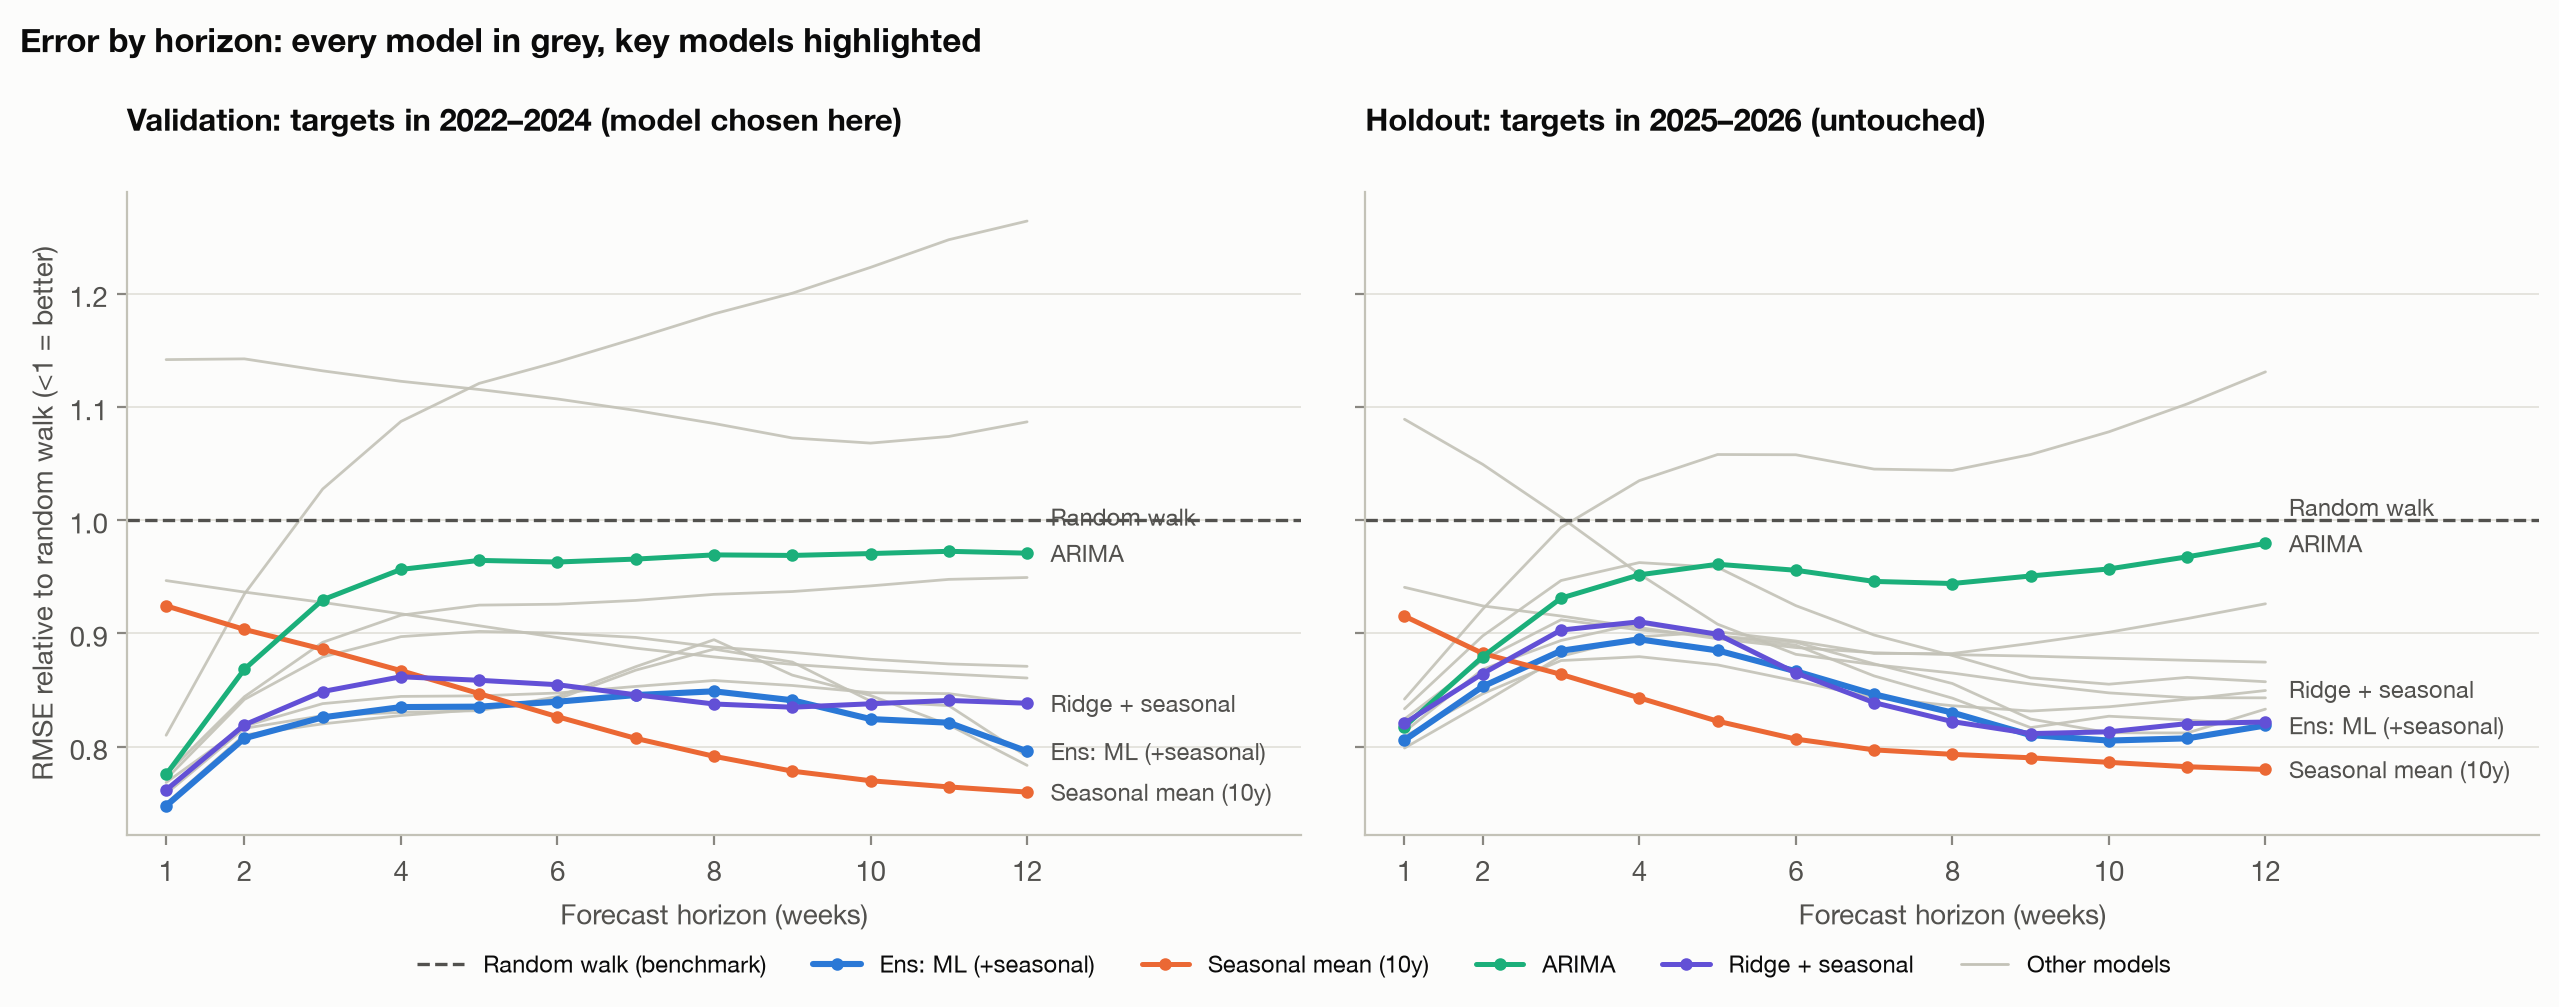

In [16]:
show(P.fig_error_by_horizon(B.accuracy_table(bt, B.by_year(*C.VALID_YEARS), C.HORIZONS),
                            B.accuracy_table(bt, B.by_year(*C.HOLDOUT_YEARS), C.HORIZONS), top))

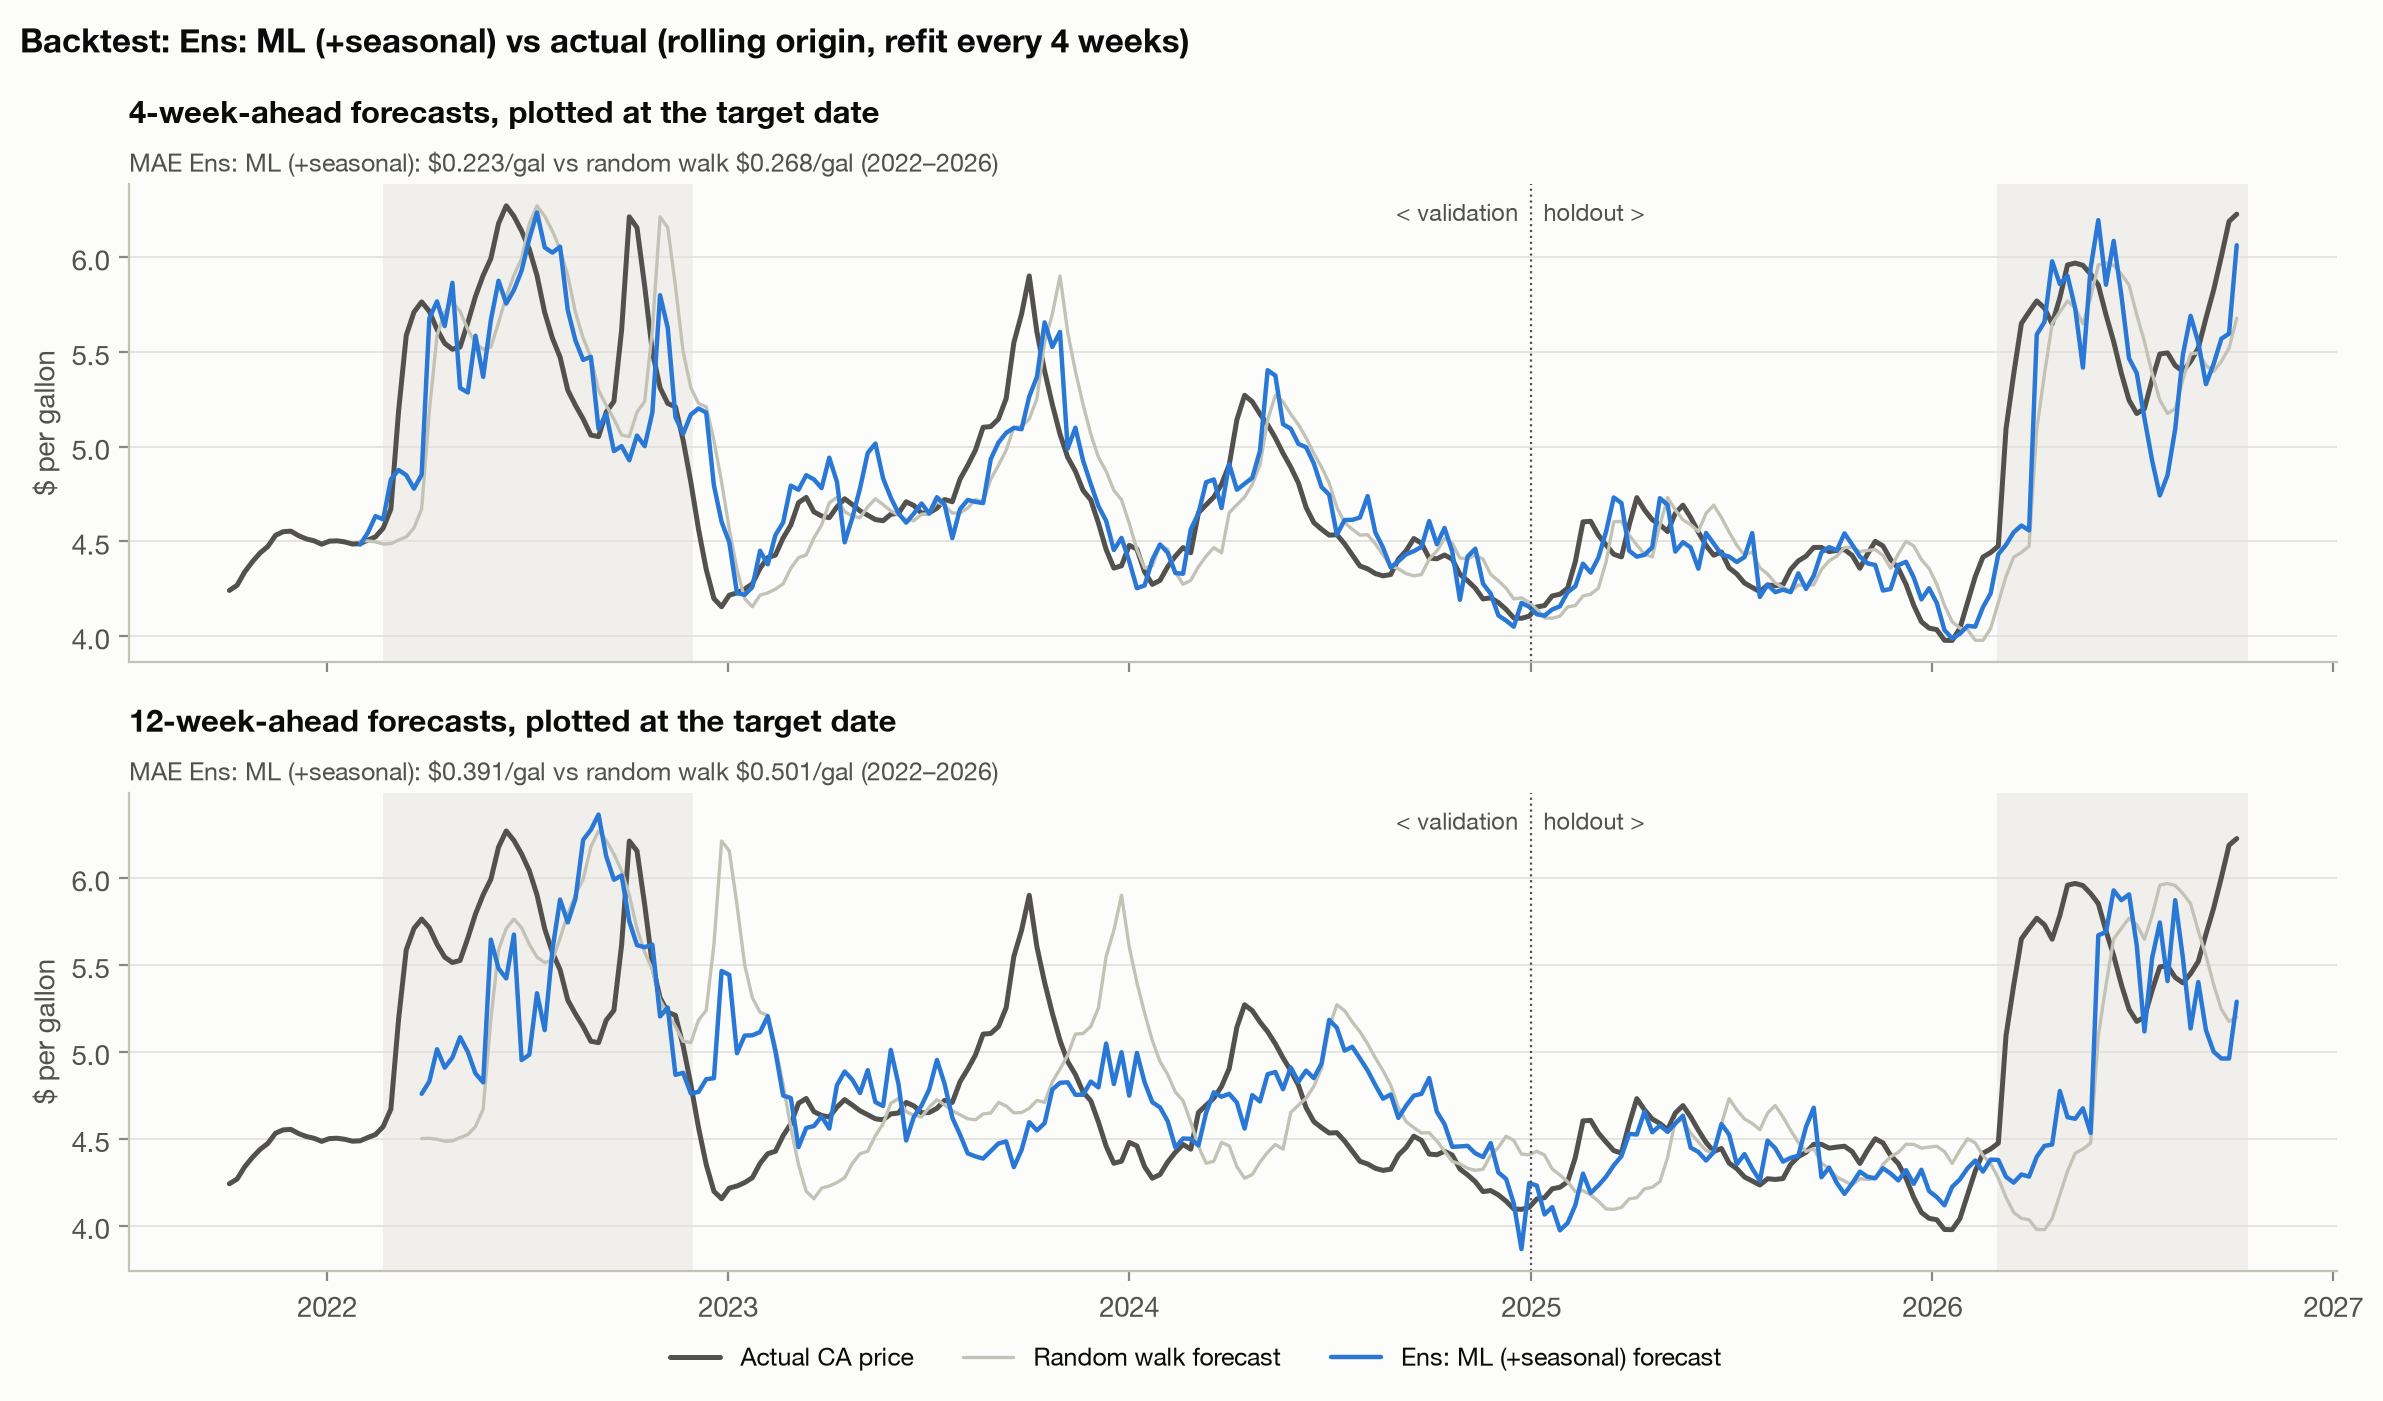

In [17]:
show(P.fig_backtest(bt, panel, top))

### Regimes: the 2022 spike, 2023–25 normal, and the 2026 shock

regime              2022 spike                   2023-25 normal                   2026 shock                  
h                           1     4     8     12             1     4     8     12         1     4     8     12
model                                                                                                         
ARIMA                     0.74  0.97  1.01  1.05           0.86  0.96  0.92  0.92       0.79  0.92  0.94  0.98
Ens: ML (+seasonal)       0.74  0.85  0.86  0.85           0.79  0.80  0.82  0.74       0.79  0.90  0.84  0.84
Random walk               1.00  1.00  1.00  1.00           1.00  1.00  1.00  1.00       1.00  1.00  1.00  1.00
Ridge + seasonal          0.75  0.87  0.83  0.88           0.79  0.85  0.83  0.79       0.81  0.92  0.84  0.84
Seasonal mean (10y)       0.92  0.86  0.78  0.73           0.97  0.91  0.82  0.79       0.87  0.81  0.77  0.77

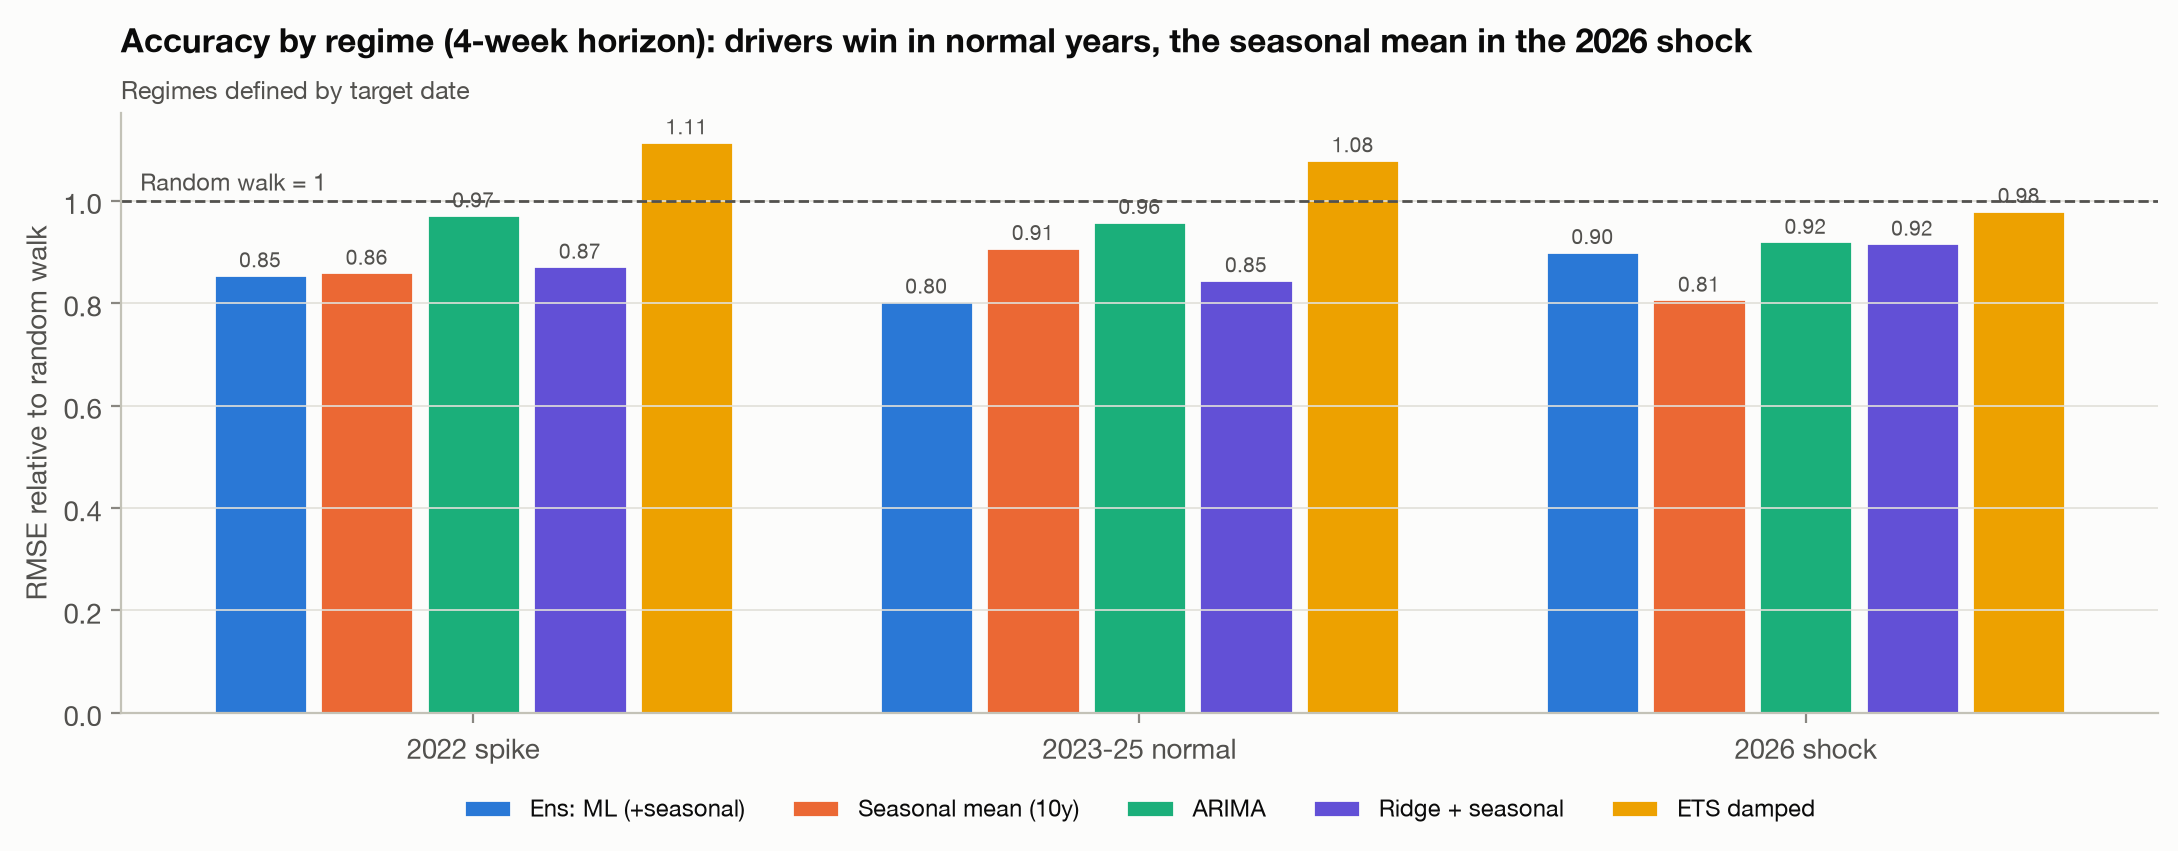

In [18]:
reg = B.regime_table(bt)
display(reg[reg.model.isin([top, "Seasonal mean (10y)", "ARIMA", "Ridge + seasonal", "Random walk"])]
        .pivot_table(index="model", columns=["regime", "h"], values="RelRMSE").round(2))
show(P.fig_regimes(reg, top))

## 7. Final 12-week forecast
Every model is refit on all data to the latest week. The top model's 80% and 90% bands are the empirical 10/90 and 5/95 quantiles of its backtest log errors at each horizon. As an honest check, bands built **only from 2022–24 errors** are tested for coverage on the 2025–26 holdout.

,h,target_date,fc_price,lo80,hi80,lo90,hi90
0,1,2026-10-12,6.241,6.126,6.344,6.091,6.420
1,2,2026-10-19,6.239,6.032,6.484,5.969,6.642
2,3,2026-10-26,6.161,5.870,6.526,5.774,6.709
3,4,2026-11-02,6.169,5.793,6.648,5.717,6.922
4,5,2026-11-09,6.229,5.797,6.832,5.702,7.108
5,6,2026-11-16,6.208,5.716,6.985,5.611,7.247
6,7,2026-11-23,6.037,5.528,6.913,5.370,7.147
7,8,2026-11-30,5.949,5.441,6.904,5.201,7.102
8,9,2026-12-07,5.833,5.276,6.800,5.078,7.111
9,10,2026-12-14,5.661,5.126,6.660,4.855,6.957


Holdout coverage (%) of bands built from 2022-24 errors:


h,1,2,3,4,5,6,7,8,9,10,11,12
cover80,79.3,78.3,82.6,87.0,84.8,84.8,87.0,88.0,87.0,85.9,84.8,82.6
cover90,90.2,91.3,94.6,92.4,92.4,91.3,92.4,91.3,90.2,87.0,87.0,85.9


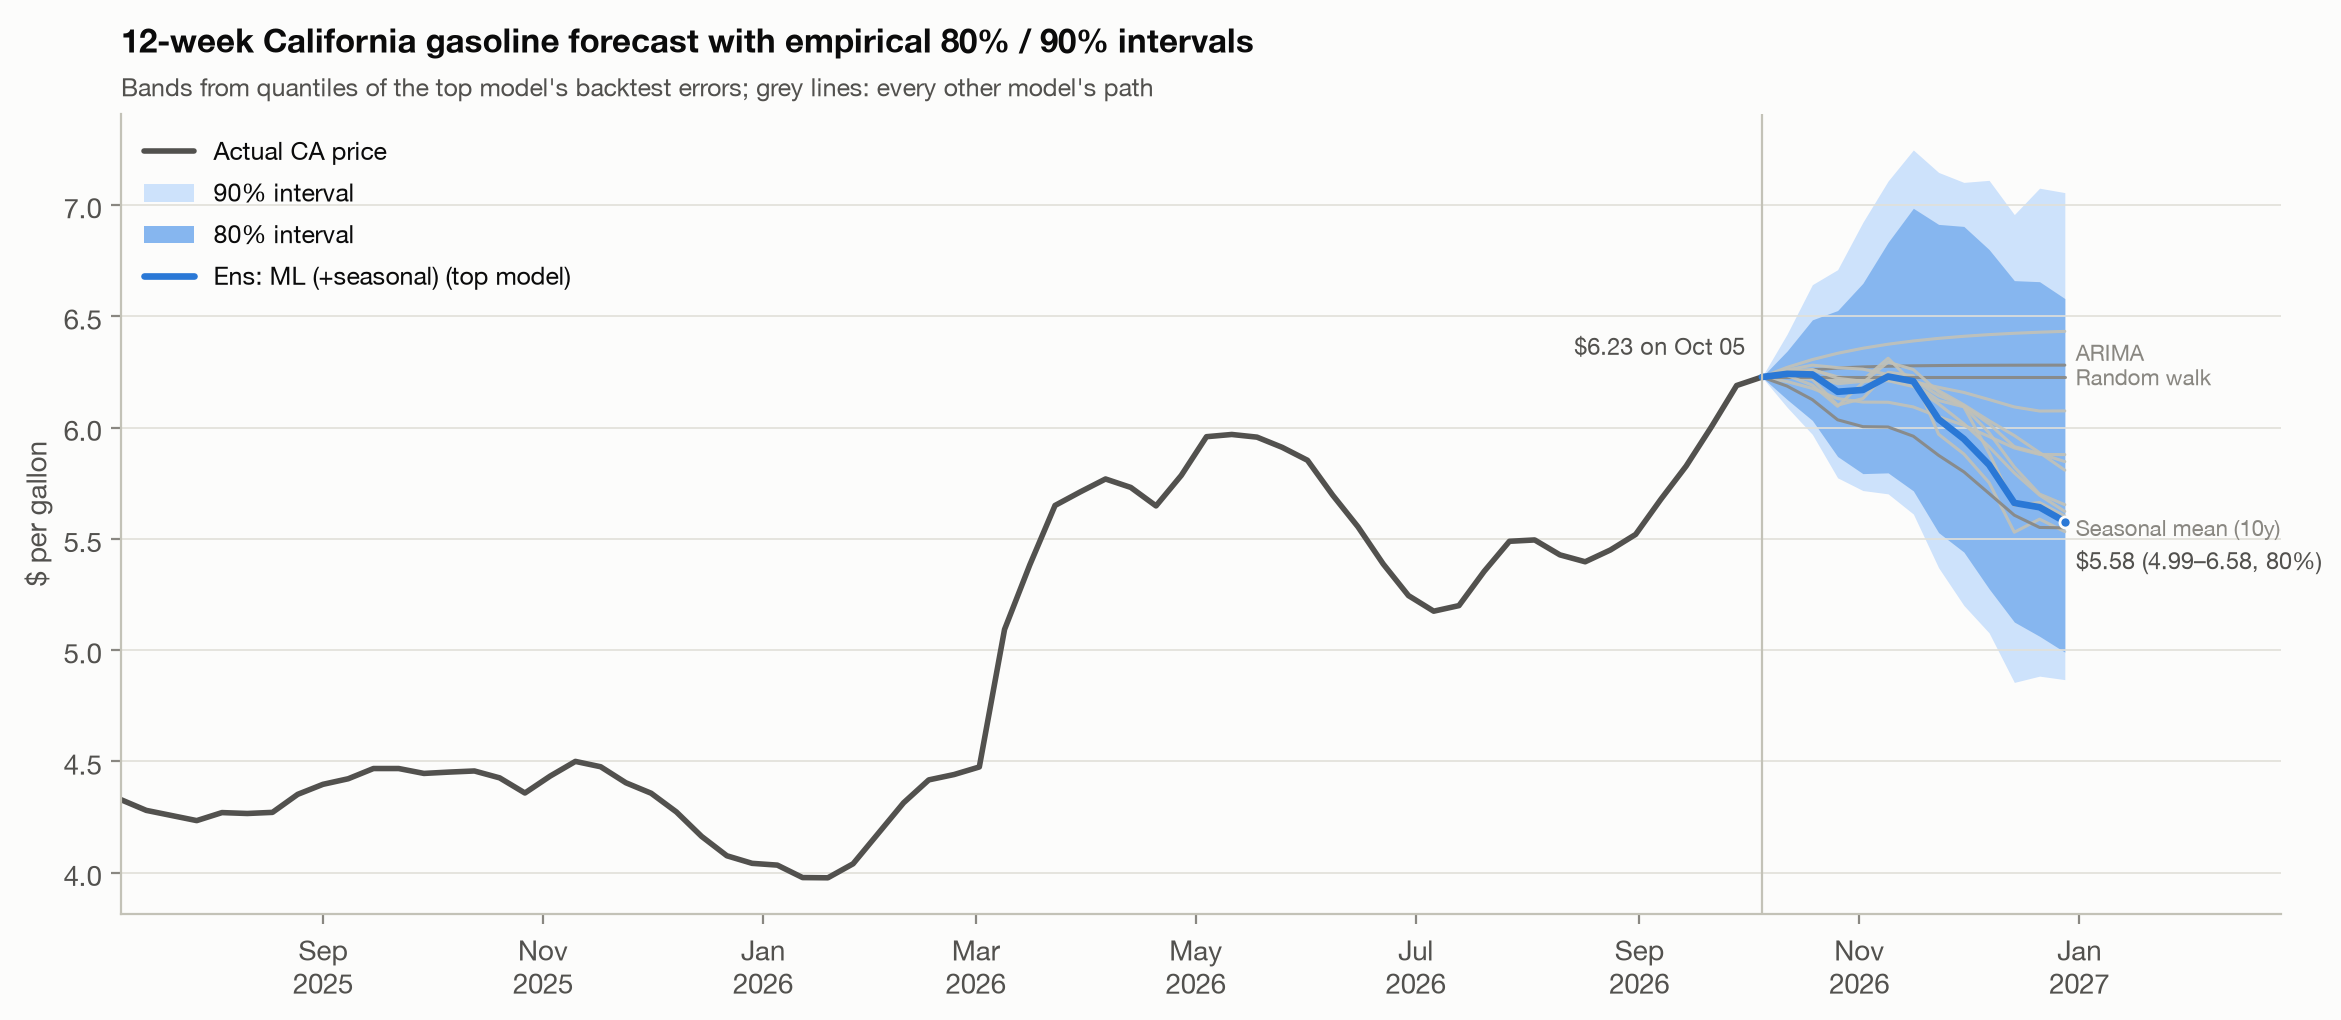

In [19]:
final, fitted = FC.final_forecast(panel, models)
q = FC.interval_quantiles(bt, top)
fan = FC.add_intervals(final, q, top)
display(fan[["h", "target_date", "fc_price", "lo80", "hi80", "lo90", "hi90"]].round(3))
cov = FC.holdout_coverage(bt, top)
print("Holdout coverage (%) of bands built from 2022-24 errors:"); display(cov.T)
show(P.fig_fan(panel, final, fan, top))

In [20]:
final.pivot(index='h', columns='model', values='fc_price').loc[[1, 4, 8, 12]].T.round(2)

h,1,4,8,12
model,,,,
ARIMA,6.25,6.27,6.28,6.28
ETS damped,6.27,6.36,6.41,6.43
Ens: ML (+seasonal),6.24,6.17,5.95,5.58
Ens: RW + seasonal mean,6.21,6.11,6.01,5.88
Ens: all models,6.24,6.21,6.10,5.85
Ens: statistical,6.23,6.21,6.16,6.07
GBM,6.23,6.21,6.09,5.60
GBM + seasonal,6.23,6.13,5.88,5.53
Random walk,6.23,6.23,6.23,6.23


## 8. What drives the forecast?

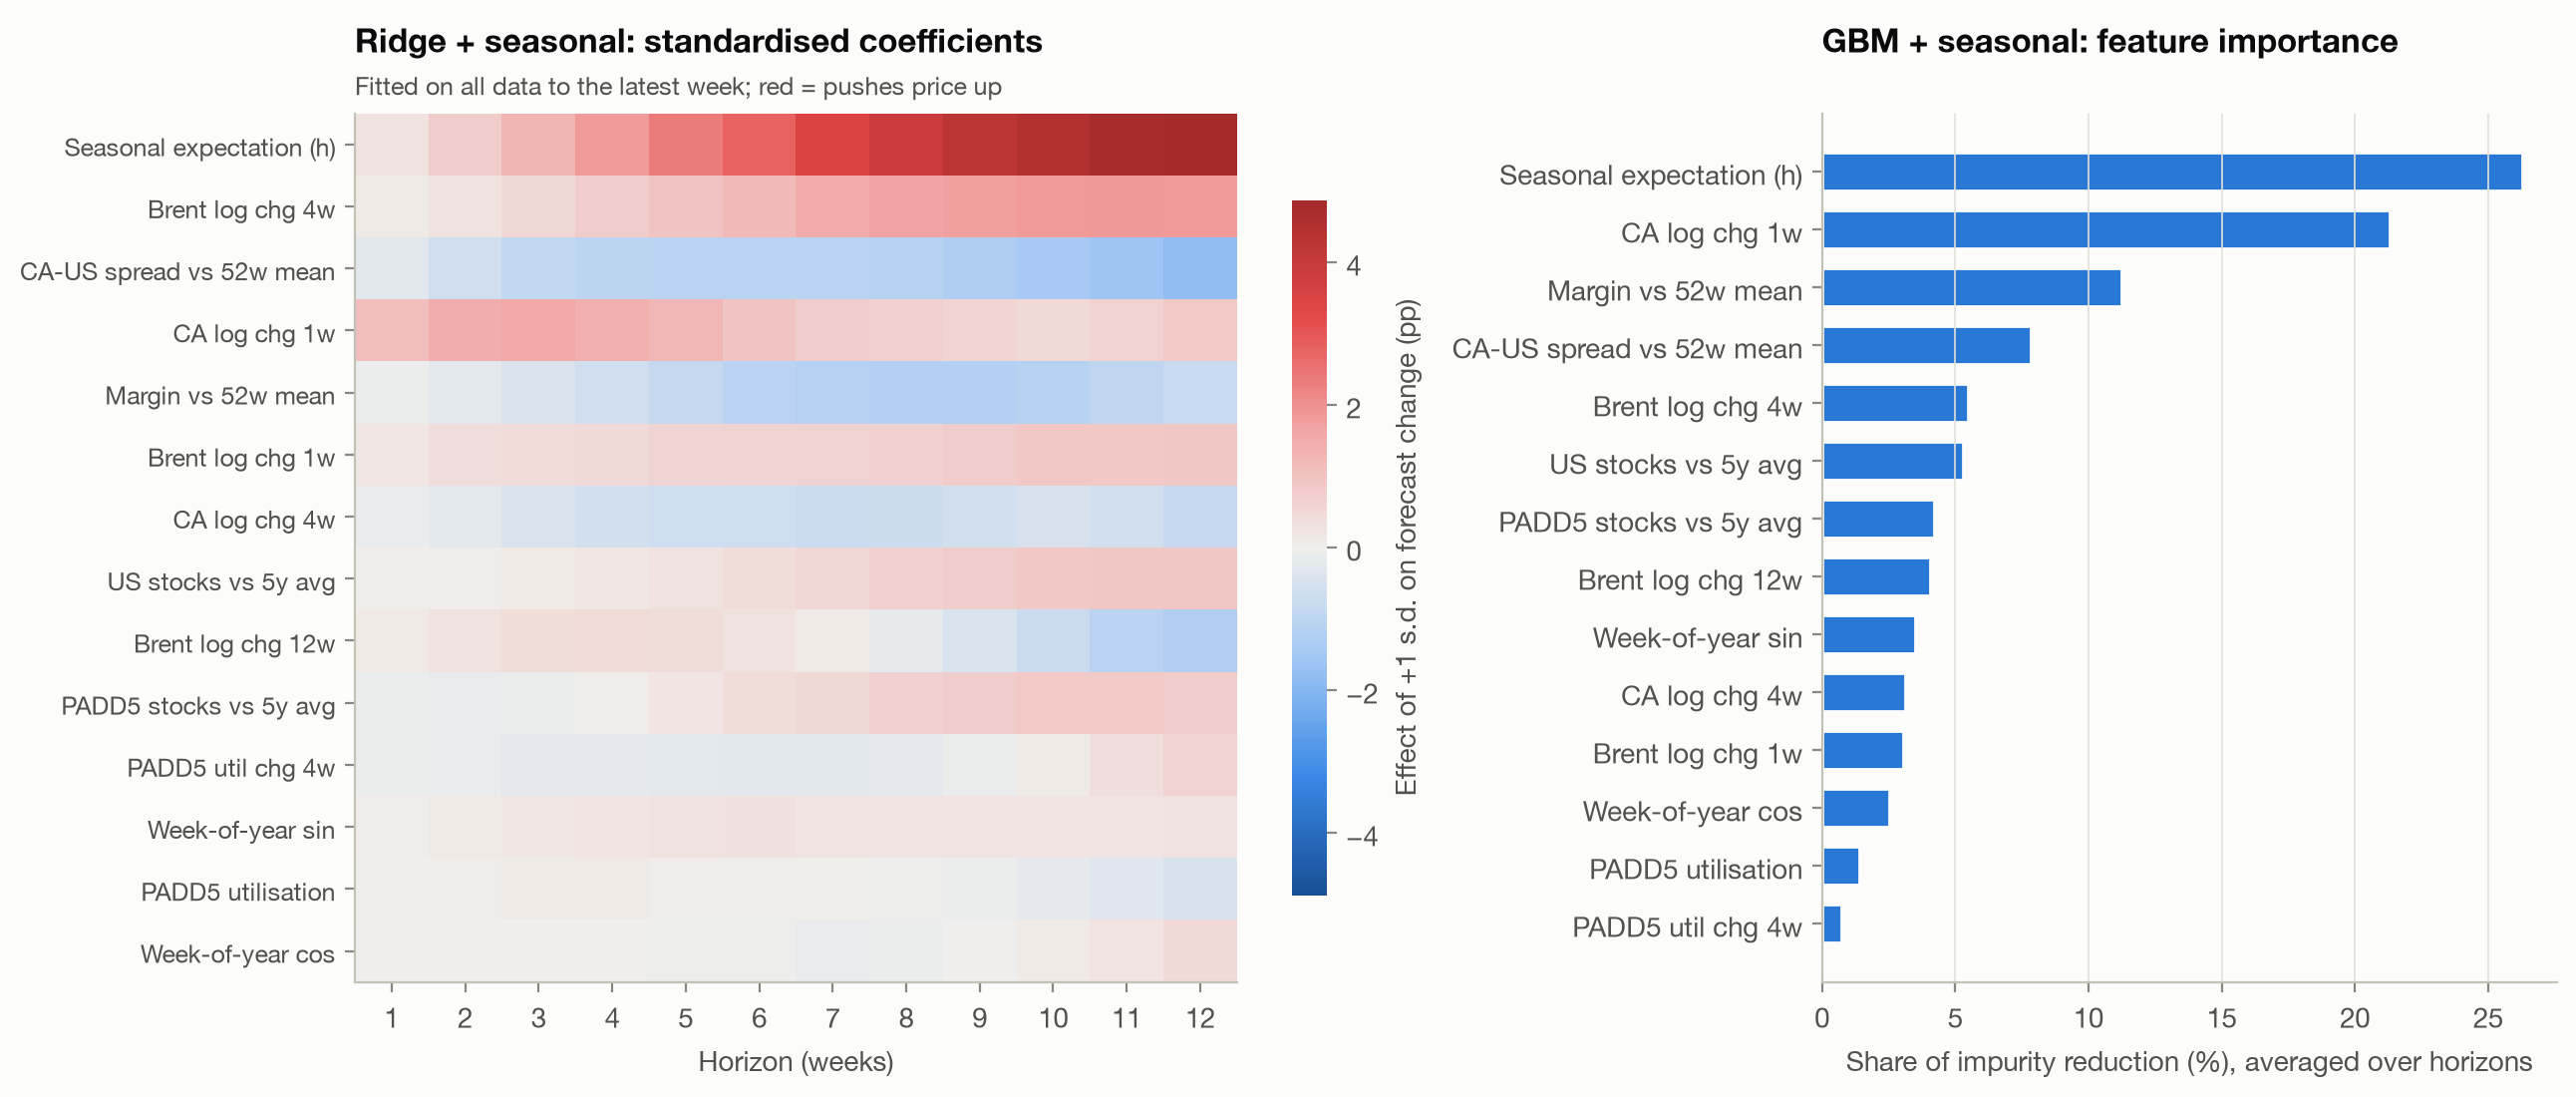

In [21]:
ridge, gbm = fitted["Ridge + seasonal"], fitted["GBM + seasonal"]
show(P.fig_importance(ridge.coefficients(), gbm.coefficients()))

**Brent scenario.** We re-run the Ridge driver model as if Brent had moved ±X% in the latest week. All three Brent-change features rise by ln(1+X), and the margin deviation falls by Brent·X/42 because pump prices have not adjusted yet. The *full pass-through* column is the mechanical crude-cost change per gallon. The same calculation powers the slider in the Streamlit app.

In [22]:
scen = pd.concat([FC.brent_scenario(panel, ridge, x).assign(brent_move_pct=x) for x in (-20, -10, 10, 20)])
scen[scen.h.isin([1, 4, 8, 12])].pivot_table(index="brent_move_pct", columns="h", values="difference").round(3)

h,1,4,8,12
brent_move_pct,,,,
-20,-0.081,-0.332,-0.498,-0.425
-10,-0.039,-0.162,-0.245,-0.208
10,0.036,0.155,0.240,0.200
20,0.070,0.304,0.475,0.394


## 9. AI component
**Option A: LLM-forecast comparison kit (`src/llm_kit.py`).** For 20 origins, 13 before and 7 after the model's stated knowledge cutoff, it writes a prompt containing **only** the data published by that origin. This is built with the same truncation function that passed the look-ahead test. The prompt asks for 1/4/8/12-week forecasts in JSON. If `ANTHROPIC_API_KEY` is set, the kit calls Claude with structured JSON output. Otherwise it saves the prompts, so the team can paste them into fresh chats with no memory and no web search. The answers are scored with the same metrics and DM tests as the models, separately for pre-cutoff origins (contamination risk) and post-cutoff origins (clean).

**Option B: Streamlit app (`app/app.py`).** It provides history charts with a driver selector, model and horizon pickers, backtest forecasts against actuals, the accuracy table, the 12-week forecast with bands, and a Brent ±X% scenario slider.

In [23]:
from src import llm_kit
manifest = llm_kit.choose_origins(panel)
print(manifest.post_cutoff.value_counts().rename({True: "post-cutoff", False: "pre-cutoff"}))
print(llm_kit.build_prompt(raw, manifest.origin.iloc[-1])[:1400], "...")
if any((C.LLM_DIR / "responses").glob("*.*")):
    display(llm_kit.score())
else:
    print("No LLM responses saved yet: run `python src/llm_kit.py prepare`, then `python src/llm_kit.py score`.")

post_cutoff
pre-cutoff     13
post-cutoff     7
Name: count, dtype: int64
You are a commodity-price forecaster. Forecast the California average retail regular
gasoline price (EIA weekly series, $/gallon, Monday survey).

Forecast origin: 2026-09-28. You may use ONLY the data below, which is exactly what was published
by that date. Do not use any knowledge of prices or events after the origin date.


Data notes:
- ca/us retail: weekly Monday prices.
- brent_prior_fri: Brent crude close on the Friday before each Monday ($/barrel; /42 = $/gallon).
- padd5 stocks (thousand barrels) and refinery utilisation (%) are for the week ending ~10 days
  before each Monday, because EIA releases them with a lag.

Last 156 weeks of data (CSV):
week_monday,ca_retail_usd_gal,us_retail_usd_gal,brent_prior_fri_usd_bbl,padd5_gas_stocks_kbbl_lagged,padd5_refinery_util_pct_lagged
2023-10-09,5.604,3.684,87.86,29339,92.6
2023-10-16,5.399,3.576,94.33,29488,85.9
2023-10-23,5.223,3.533,93.72,29682,84.4
2023-10-30

## 10. Headline results

In [24]:
def row(t, m, h): return t[(t.model == m) & (t.h == h)].iloc[0]
lines = [f"**Top model:** {top} (chosen on 2022–24 validation)", "", "| h | holdout MAE | RW MAE | RelRMSE | DM p |", "|---|---|---|---|---|"]
for h in C.REPORT_H:
    a, r = row(t_hold, top, h), row(t_hold, "Random walk", h)
    lines.append(f"| {h} | ${a.MAE:.3f} | ${r.MAE:.3f} | {a.RelRMSE:.3f} | {a.DM_p:.3f} |")
f12 = fan.iloc[-1]
lines += ["", f"**12-week forecast ({f12.target_date:%b %d, %Y}):** ${f12.fc_price:.2f}/gal "
          f"(80%: ${f12.lo80:.2f}–${f12.hi80:.2f}; 90%: ${f12.lo90:.2f}–${f12.hi90:.2f}), from ${panel.ca.iloc[-1]:.2f} on {panel.index[-1]:%b %d}."]
display(Markdown("\n".join(lines)))

**Top model:** Ens: ML (+seasonal) (chosen on 2022–24 validation)

| h | holdout MAE | RW MAE | RelRMSE | DM p |
|---|---|---|---|---|
| 1 | $0.056 | $0.077 | 0.806 | 0.005 |
| 4 | $0.206 | $0.234 | 0.895 | 0.239 |
| 8 | $0.303 | $0.362 | 0.830 | 0.166 |
| 12 | $0.342 | $0.458 | 0.819 | 0.152 |

**12-week forecast (Dec 28, 2026):** $5.58/gal (80%: $4.99–$6.58; 90%: $4.87–$7.06), from $6.23 on Oct 05.

**Takeaways**
1. **Seasonality is the backbone.** A 10-year seasonal mean alone cuts 12-week RMSE by 22–24% relative to the random walk, in both validation and holdout.
2. **Drivers add value at short horizons.** Crude momentum, margin and spread deviations, and recent CA momentum, fed through Ridge and GBM, give the biggest gains at 1–4 weeks. The ML ensemble with the seasonal feature was best on validation and beat the random walk at every horizon on the holdout. Only the 1-week gain is statistically significant there (DM p ≈ 0.005); with about 90 overlapping holdout errors, the 4–12-week gains are not.
3. **Shocks change the ranking.** In the 2026 crude shock, errors were about twice those of calm years. The plain seasonal mean beat the ML ensemble at 4–12 weeks, because crude momentum reversed sharply in June and again in September.
4. **The intervals are honest.** Bands built from 2022–24 errors covered close to their nominal share of 2025–26 outcomes, slightly over-covering at middle horizons.